# 03 — Tempos de reação e acuidade visual (Y e Z)


3– Sejam os dados de tempos de reação a um estímulo (Y) e acuidade visual (Z) de 20 indivíduos.  

| Indivíduo |  Y  |  Z  |
|----------:|----:|----:|
| 1  | 96  | 90  |
| 2  | 92  | 100 |
| 3  | 106 | 80  |
| 4  | 100 | 90  |
| 5  | 98  | 100 |
| 6  | 104 | 90  |
| 7  | 110 | 80  |
| 8  | 101 | 90  |
| 9  | 116 | 70  |
| 10 | 106 | 90  |
| 11 | 109 | 90  |
| 12 | 100 | 80  |
| 13 | 112 | 90  |
| 14 | 105 | 80  |
| 15 | 118 | 70  |
| 16 | 108 | 90  |
| 17 | 113 | 90  |
| 18 | 112 | 90  |
| 19 | 127 | 60  |
| 20 | 117 | 80  |


- Calcule a distribuição de frequências das duas variáveis aleatórias (considere a representação individual ou por classe).
- Calcule a distribuição de frequências conjunta das duas variáveis aleatórias (considere a representação individual).  
- Calcule o coeficiente de variação de cada uma das duas variáveis aleatórias e interprete-os.  
- Qual a frequência de tempo de reação a um estímulo maior que 100? Qual a frequência de tempo de reação a um estímulo menor que 120? Qual a frequência de tempo de reação a um estímulo maior que 100 e menor que 120?  
- Calcule os quartis das duas distribuições de frequências. Monte o diagrama de Box-Plot.  
- Calcule o coeficiente de correlação entre os tempos de reação a um estímulo e a acuidade visual desse conjunto de indivíduos. Interprete-o.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def mostrar_totais(tabela, colunas):
    """Mostra Σ no rodapé sem acrescentar linhas ao DataFrame de cálculo."""
    rodape = {col: (tabela[col].sum() if col in colunas else '') for col in tabela.columns}
    rodape[tabela.columns[0]] = 'Σ'
    display(pd.concat([tabela, pd.DataFrame([rodape])], ignore_index=True))


### Dados pareados e distribuições pontuais

Cada linha representa um indivíduo. A distribuição conjunta permite contar as combinações de Y e Z.


In [2]:
y=[96,92,106,100,98,104,110,101,116,106,109,100,112,105,118,108,113,112,127,117]
z=[90,100,80,90,100,90,80,90,70,100,90,80,90,80,70,90,90,90,60,80]
df=pd.DataFrame({'Indivíduo':range(1,21),'Y':y,'Z':z})
display(df)

def frequencias(v):
    t=v.value_counts().sort_index().rename_axis(v.name).reset_index(name='fi')
    t['fri']=t.fi/len(v); t['Fac']=t.fi.cumsum(); t['Fra']=t.fri.cumsum()
    return t
for col in ['Y','Z']:
    print('Variável',col)
    mostrar_totais(frequencias(df[col]),['fi','fri'])
print('Frequência conjunta: linhas Y, colunas Z')
display(pd.crosstab(df.Y,df.Z,margins=True,margins_name='Σ'))


,Indivíduo,Y,Z
0,1,96,90
1,2,92,100
2,3,106,80
3,4,100,90
4,5,98,100
5,6,104,90
6,7,110,80
7,8,101,90
8,9,116,70
9,10,106,100


Variável Y


,Y,fi,fri,Fac,Fra
0,92,1,0.05,1,0.05
1,96,1,0.05,2,0.1
2,98,1,0.05,3,0.15
3,100,2,0.10,5,0.25
4,101,1,0.05,6,0.3
5,104,1,0.05,7,0.35
6,105,1,0.05,8,0.4
7,106,2,0.10,10,0.5
8,108,1,0.05,11,0.55
9,109,1,0.05,12,0.6


Variável Z


,Z,fi,fri,Fac,Fra
0,60,1,0.05,1,0.05
1,70,2,0.10,3,0.15
2,80,5,0.25,8,0.4
3,90,9,0.45,17,0.85
4,100,3,0.15,20,1.0
5,Σ,20,1.00,,


Frequência conjunta: linhas Y, colunas Z


Z,60,70,80,90,100,Σ
Y,,,,,,
92,0,0,0,0,1,1
96,0,0,0,1,0,1
98,0,0,0,0,1,1
100,0,0,1,1,0,2
101,0,0,0,1,0,1
104,0,0,0,1,0,1
105,0,0,1,0,0,1
106,0,0,1,0,1,2
108,0,0,0,1,0,1


### Distribuições agrupadas opcionais

Seis classes para cada variável, com limites que incluem os máximos observados. Essas tabelas condensam a distribuição, mas as medidas seguintes usam os dados individuais.


In [3]:
for coluna, limites in [('Y',[92,99,106,113,120,127,134]),('Z',[60,68,76,84,92,100,108])]:
    grupos=pd.cut(df[coluna],bins=limites,right=False)
    t=grupos.value_counts(sort=False).rename_axis('Classe').reset_index(name='fi')
    t['fri']=t.fi/len(df); t['Fac']=t.fi.cumsum(); t['Fra']=t.fri.cumsum()
    print(coluna); mostrar_totais(t,['fi','fri'])


Y


,Classe,fi,fri,Fac,Fra
0,"[92, 99)",3,0.15,3,0.15
1,"[99, 106)",5,0.25,8,0.4
2,"[106, 113)",7,0.35,15,0.75
3,"[113, 120)",4,0.20,19,0.95
4,"[120, 127)",0,0.00,19,0.95
5,"[127, 134)",1,0.05,20,1.0
6,Σ,20,1.00,,


Z


,Classe,fi,fri,Fac,Fra
0,"[60, 68)",1,0.05,1,0.05
1,"[68, 76)",2,0.10,3,0.15
2,"[76, 84)",5,0.25,8,0.4
3,"[84, 92)",9,0.45,17,0.85
4,"[92, 100)",0,0.00,17,0.85
5,"[100, 108)",3,0.15,20,1.0
6,Σ,20,1.00,,


### Médias, dispersão e quartis

Para a dispersão descritiva deste conjunto usamos $\sigma=\sqrt{\sum(x_i-\bar x)^2/n}$ e $CV=\sigma/\bar x$. Os quartis abaixo usam a interpolação linear padrão do pandas; outras convenções para quartis podem gerar valores ligeiramente diferentes.


Y: média=107.50; σ=8.29; CV=7.71%; Q1=100.75; mediana=107.00; Q3=112.25
Z: média=85.50; σ=10.23; CV=11.97%; Q1=80.00; mediana=90.00; Q3=90.00
Y>100: 15 indivíduos (75%)
Y<120: 19 indivíduos (95%)
100<Y<120: 14 indivíduos (70%)


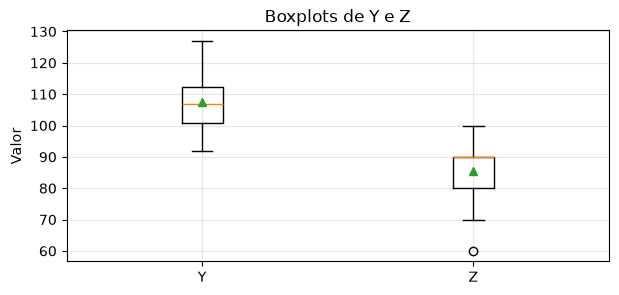

In [4]:
for col in ['Y','Z']:
    v=df[col]; media=v.mean(); dp=v.std(ddof=0)
    print(f'{col}: média={media:.2f}; σ={dp:.2f}; CV={dp/media:.2%}; Q1={v.quantile(.25):.2f}; mediana={v.median():.2f}; Q3={v.quantile(.75):.2f}')
for rotulo,cond in [('Y>100',df.Y>100),('Y<120',df.Y<120),('100<Y<120',(df.Y>100)&(df.Y<120))]:
    print(f'{rotulo}: {cond.sum()} indivíduos ({cond.mean():.0%})')
fig,ax=plt.subplots(figsize=(7,3)); ax.boxplot([df.Y,df.Z],tick_labels=['Y','Z'],showmeans=True)
ax.set(title='Boxplots de Y e Z',ylabel='Valor'); ax.grid(True,alpha=.3); plt.show()


### Correlação

A tabela explicita $\sum Y$, $\sum Z$, $\sum YZ$, $\sum Y^2$ e $\sum Z^2$. Para $r$, usam-se observações pareadas: $r=\frac{\sum YZ-n\bar Y\bar Z}{\sqrt{(\sum Y^2-n\bar Y^2)(\sum Z^2-n\bar Z^2)}}$.


,Indivíduo,Y,Z,Y·Z,Y²,Z²
0,1,96,90,8640,9216,8100
1,2,92,100,9200,8464,10000
2,3,106,80,8480,11236,6400
3,4,100,90,9000,10000,8100
4,5,98,100,9800,9604,10000
5,6,104,90,9360,10816,8100
6,7,110,80,8800,12100,6400
7,8,101,90,9090,10201,8100
8,9,116,70,8120,13456,4900
9,10,106,100,10600,11236,10000


Pearson r = -0.7282


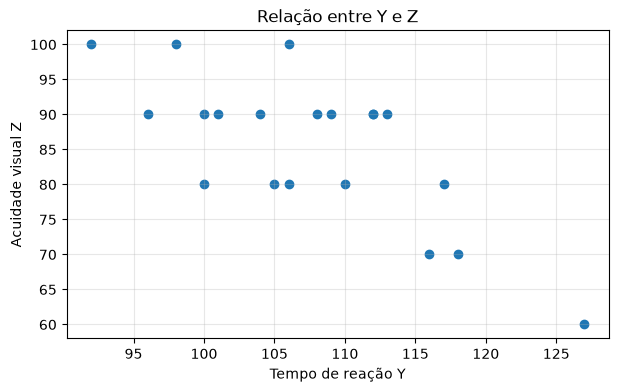

In [5]:
contas=df.copy(); contas['Y·Z']=df.Y*df.Z; contas['Y²']=df.Y**2; contas['Z²']=df.Z**2
mostrar_totais(contas,['Y','Z','Y·Z','Y²','Z²'])
r=df.Y.corr(df.Z)
print(f'Pearson r = {r:.4f}')
fig,ax=plt.subplots(figsize=(7,4)); ax.scatter(df.Y,df.Z)
ax.set(xlabel='Tempo de reação Y',ylabel='Acuidade visual Z',title='Relação entre Y e Z')
ax.grid(True,alpha=.3); plt.show()


**Interpretação:** o sinal indica a direção da associação linear; sua intensidade deve ser avaliada junto do gráfico. Associação não estabelece causalidade.
